<a href="https://colab.research.google.com/github/raisul-labs/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day-010/day-010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("stealthtechnologies/predict-student-performance-dataset")

print("Path to dataset files:", path)

100%|██████████| 12.1k/12.1k [00:00<00:00, 8.97MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/stealthtechnologies/predict-student-performance-dataset/versions/1


In [6]:
import os

print(os.listdir(path))

['data.csv']


In [7]:
df = pd.read_csv(os.path.join(path, "data.csv"))

df.head()

,Socioeconomic Score,Study Hours,Sleep Hours,Attendance (%),Grades
0,0.95822,3.4,8.2,53.0,47.0
1,0.85566,3.2,5.9,55.0,35.0
2,0.68025,3.2,9.3,41.0,32.0
3,0.25936,3.2,8.2,47.0,34.0
4,0.60447,3.8,10.0,75.0,33.0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1388 entries, 0 to 1387
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Socioeconomic Score  1388 non-null   float64
 1   Study Hours          1388 non-null   float64
 2   Sleep Hours          1388 non-null   float64
 3   Attendance (%)       1388 non-null   float64
 4   Grades               1388 non-null   float64
dtypes: float64(5)
memory usage: 54.3 KB


In [9]:
df.isnull().sum()

,0
Socioeconomic Score,0
Study Hours,0
Sleep Hours,0
Attendance (%),0
Grades,0


In [10]:
df.describe()

,Socioeconomic Score,Study Hours,Sleep Hours,Attendance (%),Grades
count,1388.000000,1388.000000,1388.000000,1388.000000,1388.000000
mean,0.552274,4.560807,8.047262,58.536023,40.691643
std,0.261272,1.897581,1.370700,11.675287,9.467358
min,0.101280,0.800000,4.800000,40.000000,32.000000
25%,0.322118,3.475000,7.000000,49.000000,34.000000
50%,0.545945,3.900000,8.400000,57.000000,35.000000
75%,0.789610,5.900000,9.100000,66.000000,47.000000
max,0.999820,10.000000,10.000000,100.000000,91.000000


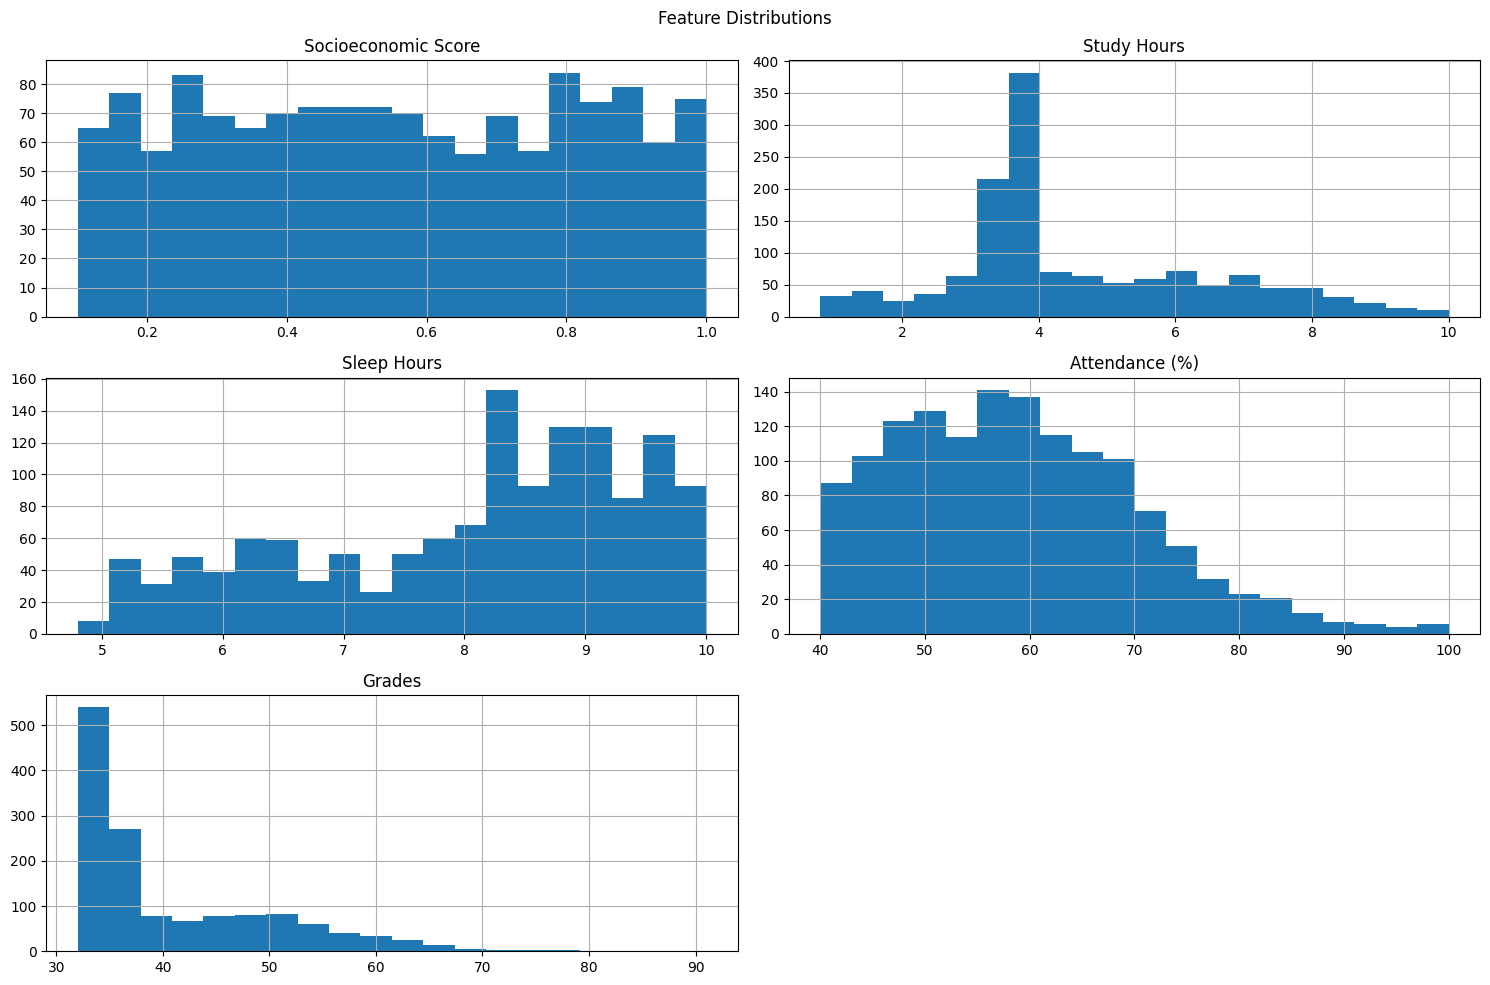

In [11]:
df.hist(figsize=(15, 10), bins=20)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

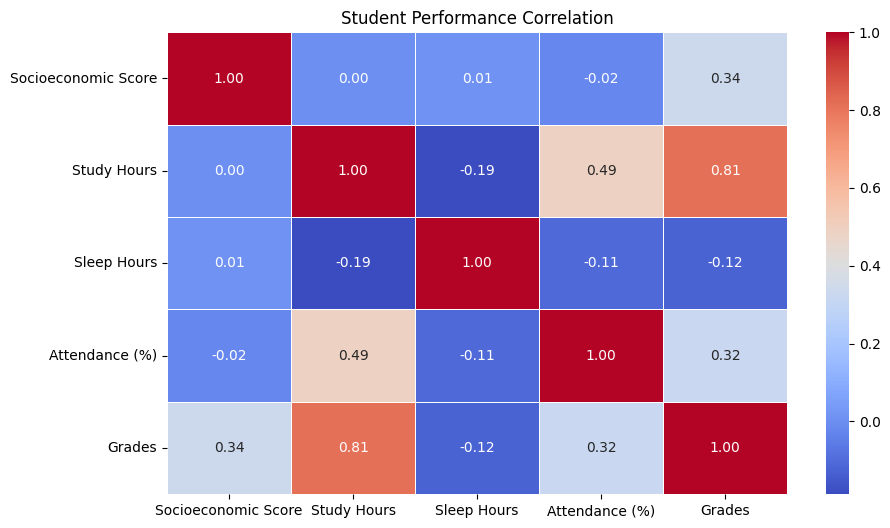

In [19]:
plt.figure(figsize=(10, 6))

corr = df.corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Student Performance Correlation")
plt.show()

In [13]:
df.columns

Index(['Socioeconomic Score', 'Study Hours', 'Sleep Hours', 'Attendance (%)',
       'Grades'],
      dtype='object')

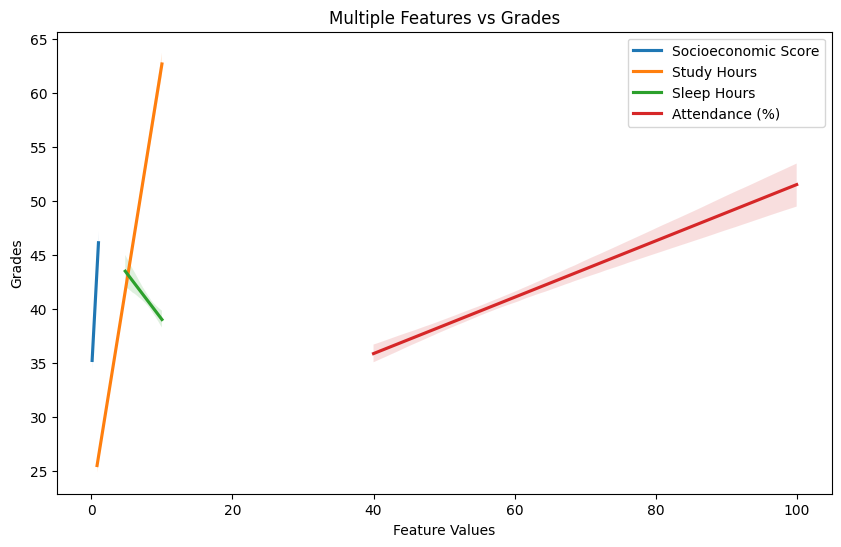

In [20]:
columns = [
    'Socioeconomic Score',
    'Study Hours',
    'Sleep Hours',
    'Attendance (%)'
]

plt.figure(figsize=(10, 6))

for col in columns:
    sns.regplot(
        data=df,
        x=col,
        y='Grades',
        scatter=False,
        label=col
    )

plt.title("Multiple Features vs Grades")
plt.xlabel("Feature Values")
plt.ylabel("Grades")
plt.legend()
plt.show()